# 01 — Synthetic Field Investigation


## Research question

Can a completely fictional spatial-temporal observation set be constructed in
a way that makes its assumptions visible and testable? The goal is not to
imitate a particular field. It is to create a controlled object for studying
spatial graphs, chronological evaluation, and diagnostic habits.

The central assumption is that a smooth spatial surface, a shared temporal
trend, site-level offsets, one localized perturbation, and random measurement
noise are enough to create useful synthetic variation. Evidence in this
notebook concerns only the generator we can inspect. A major limitation is that
none of these mechanisms establish physical realism.

In [1]:
from pathlib import Path
import hashlib
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

plt.style.use("seaborn-v0_8-whitegrid")

## Reproducible setup

Before generating observations, we record the software environment and one
explicit seed. This is evidence about computational reproducibility, not about
scientific validity. Re-running with the same library behavior should reproduce
the generated tables; changing dependencies may still alter numerical details.

In [2]:
versions = pd.Series({
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
})
versions.to_frame("version")

,version
python,3.10.11
numpy,2.2.6
pandas,2.3.3
scipy,1.15.3


In [3]:
SEED = 20261031
rng = np.random.default_rng(SEED)
N_SITES = 24
N_PERIODS = 36

## Inspect the fictional spatial domain

Sites are sampled in a normalized square. The axes have no geographic unit and
no relationship to an operational asset. Inspecting the coordinates before
constructing a response helps expose clustering, gaps, and boundary effects
that could later influence a graph or interpolator.

In [4]:
sites = pd.DataFrame({
    "site_id": [f"S{i:02d}" for i in range(N_SITES)],
    "x_norm": rng.uniform(0.05, 0.95, N_SITES),
    "y_norm": rng.uniform(0.05, 0.95, N_SITES),
    "site_offset": rng.normal(0, 0.45, N_SITES),
})
sites.shape, sites.head()

((24, 4),
   site_id    x_norm    y_norm  site_offset
 0     S00  0.369331  0.516951     0.599744
 1     S01  0.563875  0.889737     0.416120
 2     S02  0.164184  0.424377     0.806849
 3     S03  0.669615  0.561445     0.365951
 4     S04  0.846789  0.777981    -0.014144)

In [5]:
sites.dtypes.to_frame("dtype").join(
    sites.isna().sum().rename("missing")
)

,dtype,missing
site_id,object,0
x_norm,float64,0
y_norm,float64,0
site_offset,float64,0


In [6]:
assert sites["site_id"].is_unique
assert sites[["x_norm", "y_norm"]].notna().all().all()
assert sites["x_norm"].between(0, 1).all()
assert sites["y_norm"].between(0, 1).all()
sites[["x_norm", "y_norm", "site_offset"]].describe()

,x_norm,y_norm,site_offset
count,24.000000,24.000000,24.000000
mean,0.543452,0.493593,0.153240
std,0.283300,0.221870,0.473212
min,0.063082,0.050211,-0.930511
25%,0.311874,0.373955,-0.204483
50%,0.621612,0.480740,0.227083
75%,0.778159,0.624511,0.440017
max,0.937448,0.909901,1.156254


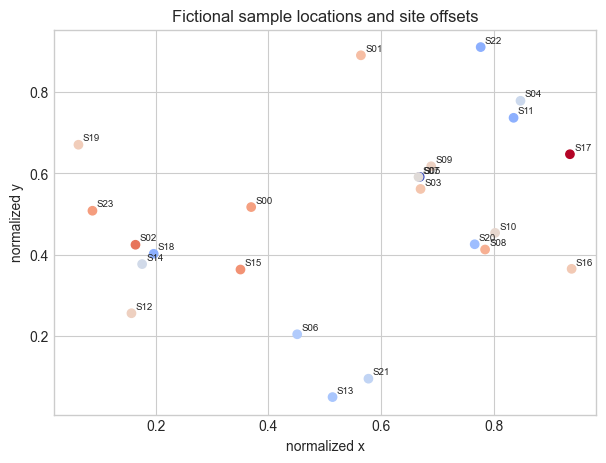

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sites["x_norm"], sites["y_norm"], c=sites["site_offset"], cmap="coolwarm")
for row in sites.itertuples():
    ax.annotate(row.site_id, (row.x_norm, row.y_norm), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="normalized x", ylabel="normalized y", title="Fictional sample locations and site offsets")
plt.show()

The coordinate checks support the intended normalized domain and show no
missing or duplicate identifiers. The plot also reveals uneven local spacing,
which is useful for later graph diagnostics. It does not support a claim about
geology or connectivity; it only describes the synthetic sampling design.

## Add time and transparent response components

The next experiment expands every site across 36 synthetic monthly periods.
Each response component is retained as a column so its contribution can be
inspected rather than hidden inside a generator function.

In [8]:
periods = pd.DataFrame({
    "period": np.arange(N_PERIODS),
    "synthetic_month": pd.period_range("2000-01", periods=N_PERIODS, freq="M").astype(str),
})
periods.head(), periods.tail()

(   period synthetic_month
 0       0         2000-01
 1       1         2000-02
 2       2         2000-03
 3       3         2000-04
 4       4         2000-05,
     period synthetic_month
 31      31         2002-08
 32      32         2002-09
 33      33         2002-10
 34      34         2002-11
 35      35         2002-12)

In [9]:
observations = sites.merge(periods, how="cross")
observations["spatial_component"] = (
    1.8 * observations["x_norm"] - 1.2 * observations["y_norm"]
    + 0.6 * np.sin(np.pi * observations["x_norm"] * observations["y_norm"])
)
observations["temporal_component"] = 0.035 * observations["period"]
observations["seasonal_component"] = 0.35 * np.sin(2 * np.pi * observations["period"] / 12)

In [10]:
distance_to_event = np.hypot(
    observations["x_norm"] - 0.72,
    observations["y_norm"] - 0.28,
)
observations["perturbation_component"] = np.where(
    observations["period"] >= 20,
    -0.9 * np.exp(-(distance_to_event / 0.22) ** 2),
    0.0,
)

In [11]:
component_columns = [column for column in observations if column.endswith("_component")]
observations[component_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
spatial_component,864.0,7.459150e-01,0.627288,-0.611058,0.300096,9.702702e-01,1.133233,1.777076
temporal_component,864.0,6.125000e-01,0.363801,0.000000,0.306250,6.125000e-01,0.918750,1.225000
seasonal_component,864.0,4.214736e-17,0.247631,-0.350000,-0.207027,2.143132e-17,0.207027,0.350000
perturbation_component,864.0,-5.612946e-02,0.131274,-0.574860,-0.021615,0.000000e+00,0.000000,0.000000


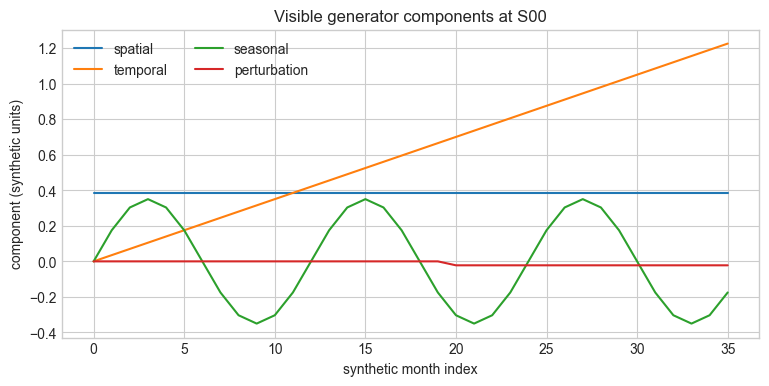

In [12]:
example = observations.query("site_id == 'S00'")
fig, ax = plt.subplots(figsize=(9, 4))
for column in component_columns:
    ax.plot(example["period"], example[column], label=column.removesuffix("_component"))
ax.set(xlabel="synthetic month index", ylabel="component (synthetic units)", title="Visible generator components at S00")
ax.legend(ncol=2)
plt.show()

The component table makes their relative scales inspectable. The localized
change begins only after period 20 and is spatially tapered by construction.
That is an experimental assumption, not an inferred event. The single-site
plot confirms the temporal ordering but cannot show the spatial footprint, so
we next inspect complete field snapshots.

In [13]:
noise = rng.normal(0, 0.16, len(observations))
observations["pressure_su_complete"] = (
    10.0 + observations[component_columns].sum(axis=1)
    + observations["site_offset"] + noise
)
observations["pressure_su_complete"].describe(percentiles=[0.05, 0.5, 0.95])

count    864.000000
mean      11.452080
std        0.786832
min        9.563770
5%        10.199644
50%       11.428242
95%       12.775964
max       14.044100
Name: pressure_su_complete, dtype: float64

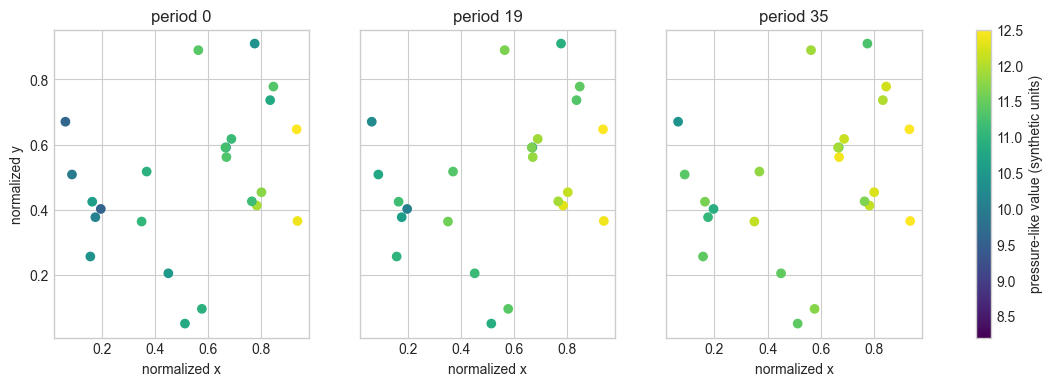

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, period in zip(axes, [0, 19, 35], strict=True):
    frame = observations.query("period == @period")
    points = ax.scatter(frame["x_norm"], frame["y_norm"], c=frame["pressure_su_complete"], vmin=8.2, vmax=12.5, cmap="viridis")
    ax.set(title=f"period {period}", xlabel="normalized x")
axes[0].set_ylabel("normalized y")
fig.colorbar(points, ax=axes, label="pressure-like value (synthetic units)")
plt.show()

The snapshots show the intended broad drift and a later localized reduction.
The fixed colour scale makes cross-period comparison possible. Evidence of a
pattern in this synthetic field is evidence that the programmed assumptions
are visible; it does not validate those assumptions against nature.

## Introduce and diagnose missing observations

Missingness is generated from a recorded random draw plus two short structured
gaps. This permits a later evaluation of coverage without pretending the
missingness mechanism is realistic. We inspect both totals and temporal
concentration before saving the data.

In [15]:
random_missing = rng.random(len(observations)) < 0.055
structured_gap = (
    observations["site_id"].isin(["S04", "S17"])
    & observations["period"].between(12, 17)
)
observations["pressure_su"] = observations["pressure_su_complete"].mask(
    random_missing | structured_gap
)
observations["is_missing"] = observations["pressure_su"].isna()

In [16]:
missing_summary = pd.DataFrame({
    "count": observations.isna().sum(),
    "percent": observations.isna().mean().mul(100).round(2),
})
missing_summary.loc[missing_summary["count"] > 0]

,count,percent
pressure_su,63,7.29


In [17]:
by_site = observations.groupby("site_id")["is_missing"].agg(["sum", "mean"])
by_period = observations.groupby("period")["is_missing"].agg(["sum", "mean"])
by_site.sort_values("mean", ascending=False).head(8)

,sum,mean
site_id,,
S04,9,0.250000
S17,6,0.166667
S23,5,0.138889
S06,4,0.111111
S13,4,0.111111
S08,3,0.083333
S21,3,0.083333
S16,3,0.083333


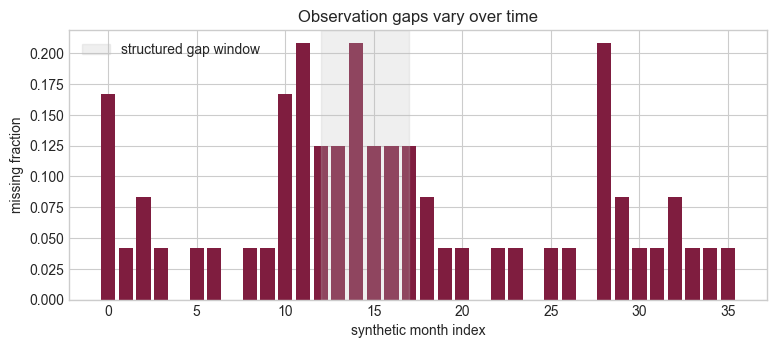

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_period.index, by_period["mean"], color="#7f1d3f")
ax.set(xlabel="synthetic month index", ylabel="missing fraction", title="Observation gaps vary over time")
ax.axvspan(12, 17, color="silver", alpha=0.25, label="structured gap window")
ax.legend()
plt.show()

In [19]:
assert observations.duplicated(["site_id", "period"]).sum() == 0
assert observations["pressure_su"].notna().mean() > 0.85
assert observations.groupby("site_id")["pressure_su"].count().min() >= 25
observations.groupby("site_id")["pressure_su"].count().describe()

count    24.000000
mean     33.375000
std       1.951866
min      27.000000
25%      33.000000
50%      34.000000
75%      35.000000
max      36.000000
Name: pressure_su, dtype: float64

The evidence shows overall coverage above the declared invariant, while the
two designed gaps are visible as a period-specific rise in missingness. A
single overall percentage would have concealed that structure. The mechanism
remains missing-at-random only in part, so later models must not assume uniform
coverage without checking.

## Change one assumption: measurement noise

We hold the latent response fixed and vary only the noise scale. This controlled
sensitivity check asks whether a modest parameter change visibly alters spread.
It is not parameter estimation and does not identify a preferred physical noise
model.

In [20]:
latent = observations["pressure_su_complete"] - noise
noise_rng = np.random.default_rng(SEED + 1)
sensitivity = []
for scale in [0.08, 0.16, 0.32]:
    trial = latent + noise_rng.normal(0, scale, len(latent))
    sensitivity.append({
        "noise_scale": scale,
        "std": trial.std(),
        "q05": trial.quantile(0.05),
        "q95": trial.quantile(0.95),
    })
pd.DataFrame(sensitivity)

,noise_scale,std,q05,q95
0,0.08,0.780191,10.179462,12.785987
1,0.16,0.798650,10.184338,12.776129
2,0.32,0.838095,10.071958,12.833929


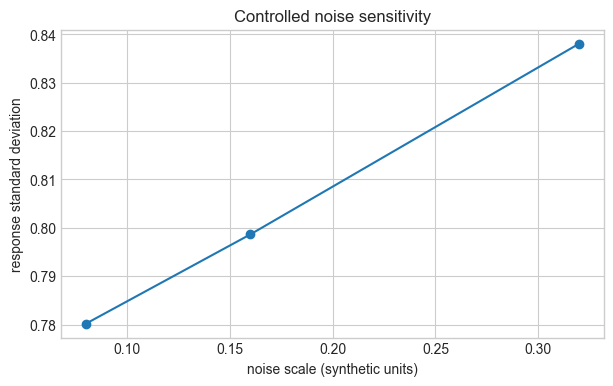

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([row["noise_scale"] for row in sensitivity], [row["std"] for row in sensitivity], marker="o")
ax.set(xlabel="noise scale (synthetic units)", ylabel="response standard deviation", title="Controlled noise sensitivity")
plt.show()

The total spread increases only modestly because spatial, temporal, and site
components already contribute variation. That observation supports keeping
noise scale explicit in later comparisons. It does not establish that any of
the three trial values is scientifically appropriate.

## Save a compact, reproducible research artifact

Only synthetic tables are written. Generator components remain present so a
reader can audit how the final value arose. The checksum is a reproducibility
diagnostic for this execution and dependency environment, not a permanent data
standard.

In [22]:
public_columns = [
    "site_id", "x_norm", "y_norm", "period", "synthetic_month",
    *component_columns, "site_offset", "pressure_su", "is_missing",
]
artifact = observations[public_columns].copy()
csv_bytes = artifact.to_csv(index=False, float_format="%.8f").encode()
hashlib.sha256(csv_bytes).hexdigest(), artifact.shape

('ec06b923683a56714abdc2527253f140f4f8cedcd9190463695082f8a0ea2c5f', (864, 12))

In [23]:
output_dir = Path("data/generated")
output_dir.mkdir(parents=True, exist_ok=True)
artifact.to_csv(output_dir / "observations.csv", index=False, float_format="%.8f")
sites.drop(columns="site_offset").to_csv(output_dir / "sites.csv", index=False, float_format="%.8f")

## Conclusion and limitations

The research question is supported in a narrow computational sense: the
fictional dataset is reproducible, its components are inspectable, its domain
and coverage satisfy declared invariants, and changing one assumption produces
a measurable response. The evidence does not establish geological realism,
causal behavior, operational usefulness, or external validity.

The next notebook should examine pairwise distances and graph connectivity
before selecting any neighbourhood rule. It should also construct evaluation
partitions only after inspecting temporal coverage, because proximity and
random row splits can create misleading evidence.